<a href="https://colab.research.google.com/github/Kathir-20/Introduction-to-AI-Module-Electronics-and-Computer-Engineering---2026-2027/blob/main/AS1%20-%20CSY%202082.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Assignment: Prediction of HousePrice and Machine Learning**

**Module Name:** CSY-2082 Introduction to AI

**My Student ID:** 25813192

In this assignment, I am using a house price dataset to explore the relationship between different property features and house prices. The dataset includes information such as property size, bedrooms, bathrooms, year built and geographical location.

I will begin by loading and analysing the original dataset then, I will then create a separate copy, clean the data and prepare the columns for analysis. After that, I will use graphs to explore house price distribution and the connections between price and other features.

For the machine learning part, I will be using Linear Regression and Random Forest Regression to predict house prices. I will also be using K-Means clustering to group similar properties and then Decision Tree and Random Forest Classification to predict the cluster groups.

My python notebook has been in the order of the work, starting with data loading and finishing with model evaluation, a final summary and my personal reflections.

**My Video Demonstration Link:** https://mymedia.northampton.ac.uk/media/AS1+Introduction+to+AI+-+Video+Demonstration_+Student+ID-25813192.mp4/0_f2vjacbw

*1*. **Libraries being Imported**


In [1]:
## Importing all the libraries required which are required for data handling, visualisation and machine learning.


import re
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO

from google.colab import auth
from google.auth import default
from google.auth.transport.requests import AuthorizedSession

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier
from sklearn.cluster import KMeans


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Imported Libraries successfully.")

Imported Libraries successfully.


2. **Dataset being loaded from Google Drive**


In [3]:
##Code used to load the data from Google Drive and authenticate Google Colab so that the notebook can access the Excel file.
## Making it to read the Excel file into a pandas DataFrame and display a sample to check that the dataset has loaded correctly.

def load_data():
    # Authenticate to access my Kathir's Google Drive
    auth.authenticate_user()

    credentials, _ = default()
    drive_session = AuthorizedSession(credentials)

    # Google Drive's Excel sheet file ID
    file_id = "17Hj53tG2U3ib3TfrslGthGCyuqbdFAJ3"
    download_url = f"https://www.googleapis.com/drive/v3/files/{file_id}?alt=media"

    print("Currently loading the house price dataset")
    response = drive_session.get(download_url)
    response.raise_for_status()

    data = pd.read_excel(BytesIO(response.content), sheet_name=0)

    print("Successfully Loaded the Dataset.")
    print(f"Rows: {data.shape[0]:,}")
    print(f"Columns: {data.shape[1]}")
    return data


df = load_data()
display(df.head())

Currently loading the house price dataset
Successfully Loaded the Dataset.
Rows: 30,006
Columns: 15


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,895900,"3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,247000,"1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,44900,"1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,959000,"1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,532000.0,"6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,83500,440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,52000.0,"251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


3. **Understanding the Dataset**

Before making the changes, I wanted to understand what information is available in the original dataset so I would check the number of records data types, missing values and the duplicate records. I will then  also look at the statistical description to understand the what are the range of the numerical values presented.

This first check helps me decide which columns needs cleaning and which information will be useful for the house price prediction. I will keep the original dataset unchanged so that I can compare it with the processed dataset later on.

In [5]:
## Analysing the initial original data before making any changes then checking the number of rows and columns, names of the columns and data types.
## Checking missing values and duplicate records and reviewing the statistical description of the numerical columns.

print("Shape of the Dataset:")
print(df.shape)

print("\nColumn names-")
print(df.columns.tolist())
print("\nDataset information-")
df.info()

print("\nMissing values in each column-")
display(df.isnull().sum().to_frame("The missing values"))
print("\nTotal missing values-")
print(df.isnull().sum().sum())

print("\nDuplicate records-")
print(df.duplicated().sum())

print("\nStatistical description of numerical columns-")
display(df.describe())

Shape of the Dataset:
(30006, 15)

Column names-
['Price', 'Sqr Ft', 'Longitude', 'Latitude', 'Lot Size', 'Beds', 'Bath', 'Year Built', 'Last Sold Year', 'Last Sold For', 'Address', 'City', 'State', 'Zipcode', 'Address Full']

Dataset information-
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30006 entries, 0 to 30005
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Price           30006 non-null  object 
 1   Sqr Ft          27786 non-null  object 
 2   Longitude       30006 non-null  float64
 3   Latitude        30006 non-null  float64
 4   Lot Size        25490 non-null  object 
 5   Beds            27420 non-null  float64
 6   Bath            27496 non-null  float64
 7   Year Built      26258 non-null  float64
 8   Last Sold Year  14213 non-null  float64
 9   Last Sold For   14213 non-null  float64
 10  Address         30006 non-null  object 
 11  City            30006 non-null  object 
 12  State   

,The missing values
Price,0
Sqr Ft,2220
Longitude,0
Latitude,0
Lot Size,4516
Beds,2586
Bath,2510
Year Built,3748
Last Sold Year,15793
Last Sold For,15793



Total missing values-
47169

Duplicate records-
8

Statistical description of numerical columns-


,Longitude,Latitude,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Zipcode
count,30006.000000,30006.000000,27420.000000,27496.000000,26258.000000,14213.000000,1.421300e+04,30003.000000
mean,-95.167341,36.158007,3.288658,2.578688,1973.140224,2011.110673,3.469467e+05,59349.268440
std,15.454027,5.500075,1.472238,1.448891,34.512400,6.596002,1.187349e+06,27206.130444
min,-150.047160,25.550295,1.000000,0.750000,1800.000000,1987.000000,1.000000e+00,2108.000000
25%,-106.742751,32.747084,3.000000,2.000000,1950.000000,2006.000000,1.130000e+05,33137.000000
50%,-93.390977,36.016481,3.000000,2.000000,1978.000000,2013.000000,2.098000e+05,68124.000000
75%,-81.638904,40.017658,4.000000,3.000000,2004.000000,2017.000000,3.760000e+05,85016.000000
max,-70.997740,61.442024,65.000000,98.000000,2019.000000,2019.000000,1.200000e+08,99587.000000


4. **Creating an Individual Working Table**

new_sheet is the copy ofthe original dataset that will be cleaned.

In [42]:
# #Analysing the original data before making any changes and checking the number of rows and columns, column's names and data types.
## Checking missing values and duplicate records and reviewing the statistical description of the numerical columns.

original_sheet = df.copy(deep=True)
new_sheet = original_sheet.copy(deep=True)

print("Shape of Original Dataset:", original_sheet.shape)
print("Shape of Working Dataset shape:", new_sheet.shape)
display(new_sheet.head())

Original dataset shape: (30006, 15)
Working dataset shape: (30006, 15)


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,895900,"3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,247000,"1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,44900,"1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,959000,"1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,532000.0,"6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,83500,440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,52000.0,"251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


5. **Data Preparation and Cleaning**

In this section, I am preparing the dataset so that the values will be used for machine learning as well as for visualisation . Some columns may contain symbols such as dollar signs, commas or text units. These need to be removed before the values can be converted into numeric format.

I will also use the full address to fill the  missing ZIP codes where a five digit value is available. Once this has been completed, I can remove address related columns which are not required. I will keep useful property and location features, including Lot Size, Longitude and Latitude

In [43]:
# #The code cleans the numeric columns by removing currency symbols, commas and text units and convert the cleaned values into numeric data types.
## The decimal values are retained where they are present and the invalid entries become missing values.

def clean_numeric_column(series):
                # Keeping digits, decimal points and minus signs,, converts the invalid entries to NaN
    cleaned = (
        series.astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"[^0-9.\-]", "", regex=True)
        .replace("", pd.NA)
    )
    return pd.to_numeric(cleaned, errors="coerce")


# Converts the price and numeric property features where these columns exist
numeric_columns_to_clean = [
    "Price", "Sqr Ft", "Lot Size", "Beds", "Bath",
    "Year Built", "Longitude", "Latitude"
]
for column in numeric_columns_to_clean:
    if column in new_sheet.columns:
        new_sheet[column] = clean_numeric_column(new_sheet[column])

print("Numeric conversion has been completed.")


display(new_sheet[[c for c in numeric_columns_to_clean if c in new_sheet.columns]].head())

Numeric conversion completed.


,Price,Sqr Ft,Lot Size,Beds,Bath,Year Built,Longitude,Latitude
0,895900,3447,7895.0,4.0,4.5,2019.0,-112.081985,33.560055
1,247000,1767,7877.0,3.0,2.0,1954.0,-96.67625,32.829227
2,44900,1232,3510.0,3.0,1.0,1900.0,-78.82519,42.913
3,959000,1417,2598.0,3.0,2.0,1939.0,-73.86017,40.72296
4,83500,440,<NA>,<NA>,1.0,1971.0,-80.206314,25.937965


5.2 **Filling the missing ZIP Codes from the full address**

The code looks for the five digit zip code in Address Full section. It fills only missing zip code values and leaves existing ZIP codes unchanged. zip codes remain strings to preserve any leading zero.

In [71]:
## Filling the missing zip codes using the five digit value found in the full address and replacing only missing ZIP-code cells and keep existing values unchanged.
# #Keeping ZIp codes as text so that leading zeros are not lost.

if "Zipcode" in new_sheet.columns and "Address Full" in new_sheet.columns:
    address_zip = new_sheet["Address Full"].astype("string").str.extract(
        r"(\b\d{5}\b)", expand=False
    )

    missing_zip = new_sheet["Zipcode"].isna() | (
        new_sheet["Zipcode"].astype("string").str.strip() == ""
    )

    new_sheet.loc[missing_zip, "Zipcode"] = address_zip.loc[missing_zip]

    # Standardising the zip code values as strings without converting them to numbers
    new_sheet["Zipcode"] = new_sheet["Zipcode"].astype("string").str.extract(
        r"(\d{5})", expand=False
    )

    print("Missing ZIP codes after the address extraction -",
          new_sheet["Zipcode"].isna().sum())
else:
    print("Zipcode or Address Full column is not found , ZIP extraction been skipped.")

Zipcode or Address Full column not found; ZIP extraction skipped.


5.3 **Removing the duplicate records and rows without a target price**

Rows without a valid house price cannot be used to train a house price prediction model, so they are removed and duplicate rows are also removed.

In [45]:
## This code cell removes duplicate records and rows without a valid house price,
# A record without a valid target price cannot be used for house price prediction.

rows_before = len(new_sheet)
new_sheet = new_sheet.drop_duplicates()


if "Price" in new_sheet.columns:
    new_sheet = new_sheet.dropna(subset=["Price"])
    new_sheet = new_sheet[new_sheet["Price"] > 0]

print("Rows beforecleaning-", rows_before)

print("Rows after removing the duplicates and invalid or missing prices-", len(new_sheet))
print("Rows removed- ", rows_before - len(new_sheet))

Rows before cleaning: 30006
Rows after removing duplicates and invalid/missing prices: 29771
Rows removed: 235


5.4 **Removes the columns that are not required for modelling**

Address Full is retained until zip extraction is complete. Address text fields and previous sale fields are removed from the modelling dataset. Lot Size, longitude and latitude are retained because they may contain useful property or location information.

In [46]:
## Removes the columns that are not required for the analysis or predictio and address Full is removed after using it to fill missing ZIP codes.
# Im Keeping the useful property and location features such as Lot Size, Longitude and Latitude.

columns_to_remove = [
    "Address Full", "Address", "City", "State",
    "Last Sold Year", "Last Sold For"
]

existing_columns_to_remove = [
    column for column in columns_to_remove
    if column in new_sheet.columns
]



new_sheet = new_sheet.drop(columns=existing_columns_to_remove)

print("Removed columns:", existing_columns_to_remove)

print("Remaining columns:")

print(new_sheet.columns.tolist())

Removed columns: ['Address Full', 'Address', 'City', 'State', 'Last Sold Year', 'Last Sold For']
Remaining columns:
['Price', 'Sqr Ft', 'Longitude', 'Latitude', 'Lot Size', 'Beds', 'Bath', 'Year Built', 'Zipcode']


5.5 **Check the cleaned dataset**

In [47]:
## Analyse the original data before making any changes and checking the number of rows and columns etc.
# Checking missing values and duplicate records.
## Review the statistical description of the numerical columns.

print("Cleaned dataset  shape-", new_sheet.shape)

print("\nData types and non  null counts-")

new_sheet.info()

print("\nMissing values after the cleaning-")

display(new_sheet.isnull().sum().to_frame("missing values"))

print("\nstatistical description after the cleaning-")

display(new_sheet.describe())

print("\nFirst five cleaned records displayed-")

display(new_sheet.head())

Cleaned dataset shape: (29771, 9)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
Index: 29771 entries, 0 to 30005
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Price       29771 non-null  Int64  
 1   Sqr Ft      27568 non-null  Int64  
 2   Longitude   29770 non-null  Float64
 3   Latitude    29771 non-null  Float64
 4   Lot Size    25278 non-null  Float64
 5   Beds        27236 non-null  Float64
 6   Bath        27303 non-null  Float64
 7   Year Built  26043 non-null  Float64
 8   Zipcode     29484 non-null  string 
dtypes: Float64(6), Int64(2), string(1)
memory usage: 2.5 MB

Missing values after cleaning:


,Missing values
Price,0
Sqr Ft,2203
Longitude,1
Latitude,0
Lot Size,4493
Beds,2535
Bath,2468
Year Built,3728
Zipcode,287



Statistical description after cleaning:


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built
count,29771.0,27568.0,29770.0,29771.0,25278.0,27236.0,27303.0,26043.0
mean,529864.203386,5106.970727,-95.167792,36.152997,5380.813429,3.289213,2.582973,1973.192528
std,1141364.054712,249459.347741,15.452508,5.50061,230148.656137,1.474822,1.45085,34.516356
min,1.0,1.0,-150.04716,25.550295,0.25,1.0,0.75,1800.0
25%,185000.0,1288.0,-106.742482,32.745567,1.95,3.0,2.0,1950.0
50%,309900.0,1800.0,-93.390977,36.014896,3920.0,3.0,2.0,1978.0
75%,534700.0,2547.0,-81.639385,40.016833,6875.0,4.0,3.0,2004.0
max,60000000.0,36003799.0,-70.99774,61.442024,36590400.0,65.0,98.0,2019.0



First five cleaned records:


,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Zipcode
0,895900,3447,-112.081985,33.560055,7895.0,4.0,4.5,2019.0,85021
1,247000,1767,-96.67625,32.829227,7877.0,3.0,2.0,1954.0,75228
2,44900,1232,-78.82519,42.913,3510.0,3.0,1.0,1900.0,14211
3,959000,1417,-73.86017,40.72296,2598.0,3.0,2.0,1939.0,11374
4,83500,440,-80.206314,25.937965,<NA>,<NA>,1.0,1971.0,33169


6. **Data  - visualisation**

After cleaning the dataset, I will be  exploring  the information using graphs. The visualisations help me understand the distribution of house prices that is whether features such as square footage, bedrooms, bathrooms and location show any relationship with price.

I have created a common plotting function for the price comparison graphs which i can call whenever i wanted as this avoids repeating similar code for every feature and makes the notebook easier to follow.

6.1 **House price distribution**

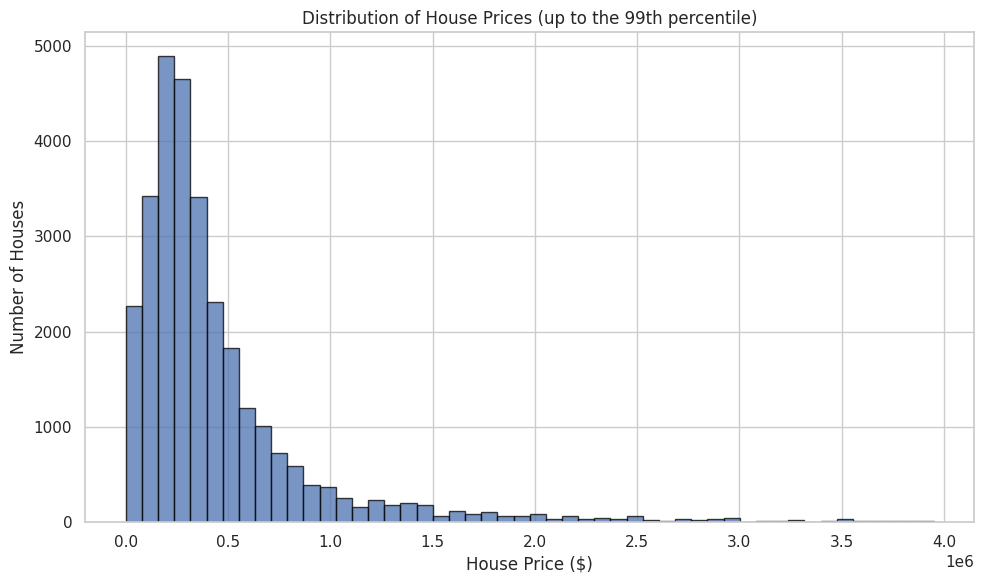

Records shown: 29477
Records above the displayed range: 294


In [48]:
## code visualises the distribution of house prices and ive used the 99th percentile as the upper display limit to make the main distribution easier to see.

price_data = new_sheet["Price"].dropna()

price_upper_limit = price_data.quantile(0.99)

plt.figure(figsize=(10, 6))
plt.hist(
    price_data[price_data <= price_upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.xlabel("House Price in $")

plt.ylabel("Number of - Houses")
plt.title("Distribution of House - Prices")
plt.tight_layout()
plt.show()

print("Records shown- ", (price_data <= price_upper_limit).sum())
print("Records above the displayed range- ", (price_data > price_upper_limit).sum())

6.2 **Geographical distribution: longitude vs latitude**

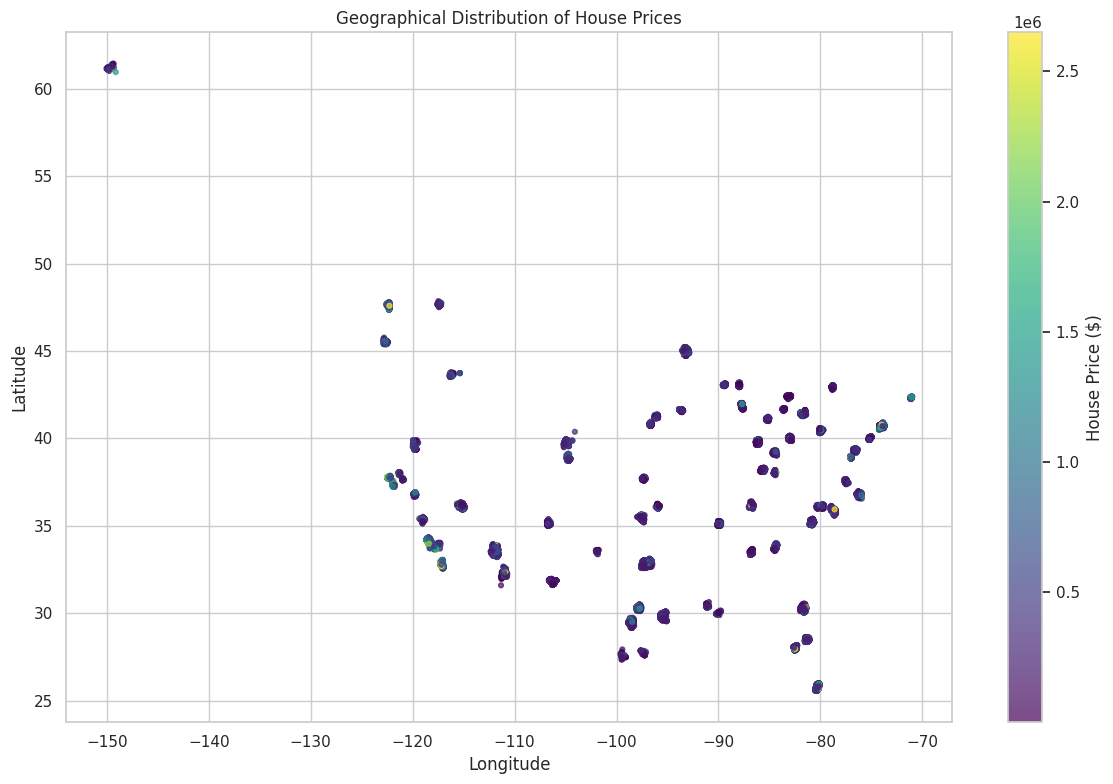

In [49]:
## Visualising the house locations using Longitude and Latitudeand using the house price as the colour of each point to compare prices across locations.

if {"Longitude", "Latitude", "Price"}.issubset(new_sheet.columns):
    location_data = new_sheet.dropna(
        subset=["Longitude", "Latitude", "Price"]
    ).copy()

    plt.figure(figsize=(12, 8))
    graph = plt.scatter(
        location_data["Longitude"],
        location_data["Latitude"],
        c=location_data["Price"],
        cmap="viridis",
        vmax=location_data["Price"].quantile(0.98),
        s=12,
        alpha=0.7
    )
    plt.colorbar(graph, label="House Price ($)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Geographical Distribution of House Prices")
    plt.tight_layout()
    plt.show()
else:
    print("Longitude,Latitude or Price is missing -  geographical graph skipped.")

6.3 **Correlation Heat Map**

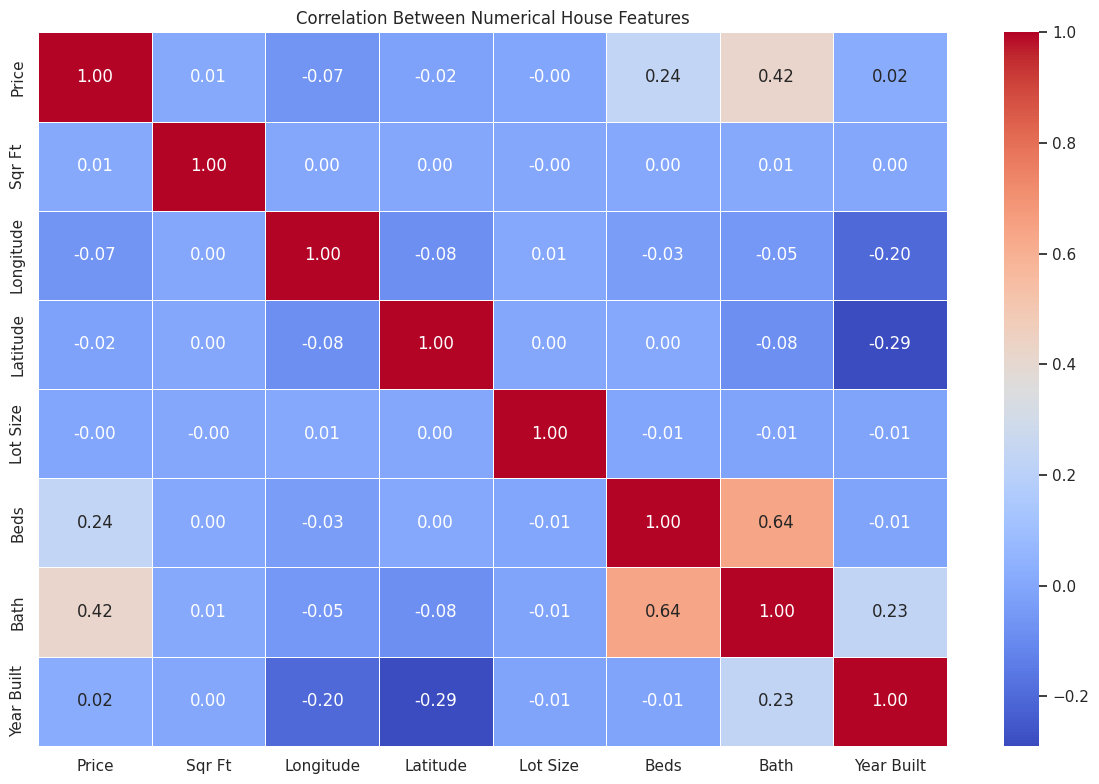

In [50]:
## this code cell visualises correlations between numerical columns using a heatmap and zip code is excluded because it is an identifier, not a numerical measurement.

numeric_data = new_sheet.select_dtypes(include=np.number).copy()

# zip code is an identifier, so it should not be treated as a numerical measurement
numeric_data = numeric_data.drop(columns=["Zipcode"], errors="ignore")

correlation = numeric_data.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation between the Numerical House Features")
plt.tight_layout()
plt.show()

6.4 **Reusable function**  -

house price vs each feature, A
common important function which avoids repeating the same plotting code as reduces codes.Each graph uses non missing values for the selected feature and price.

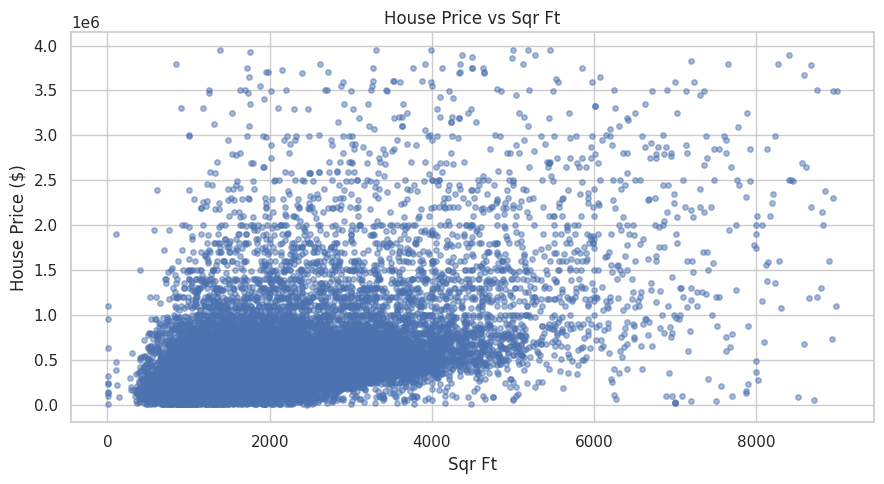

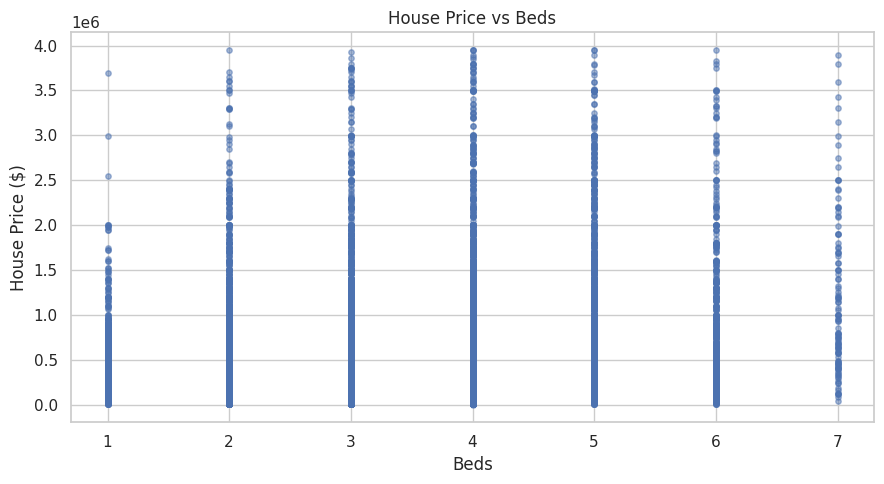

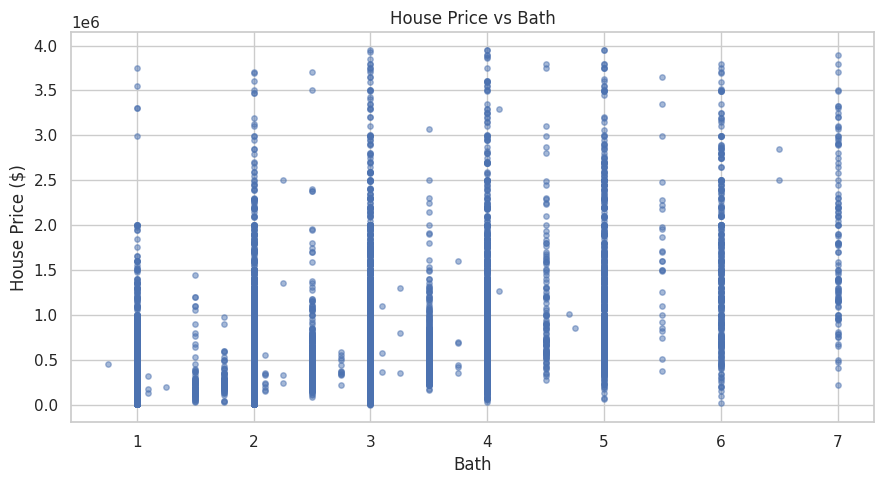

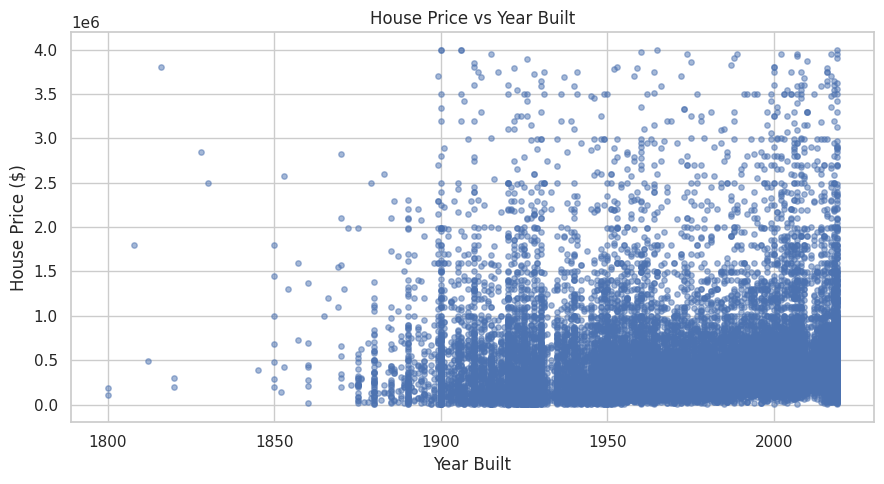

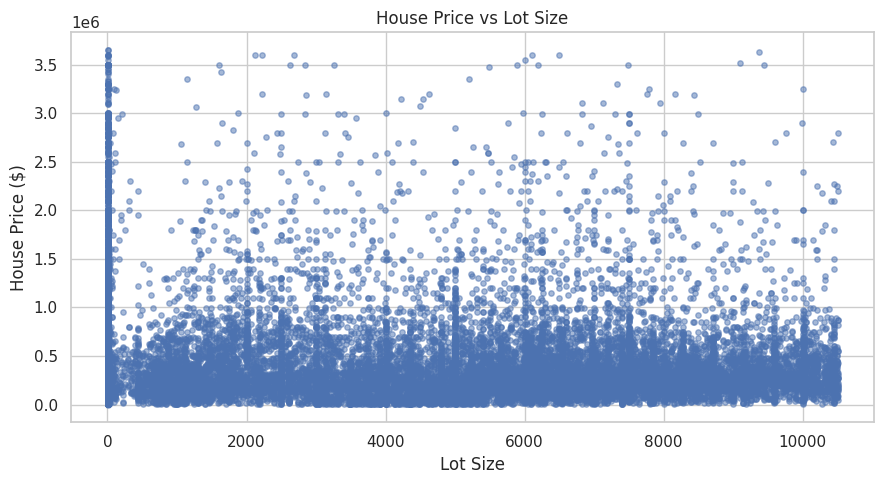

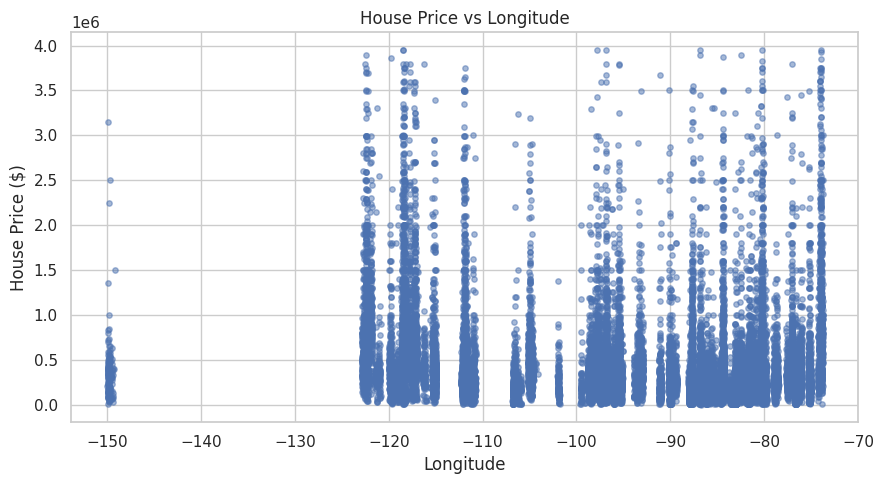

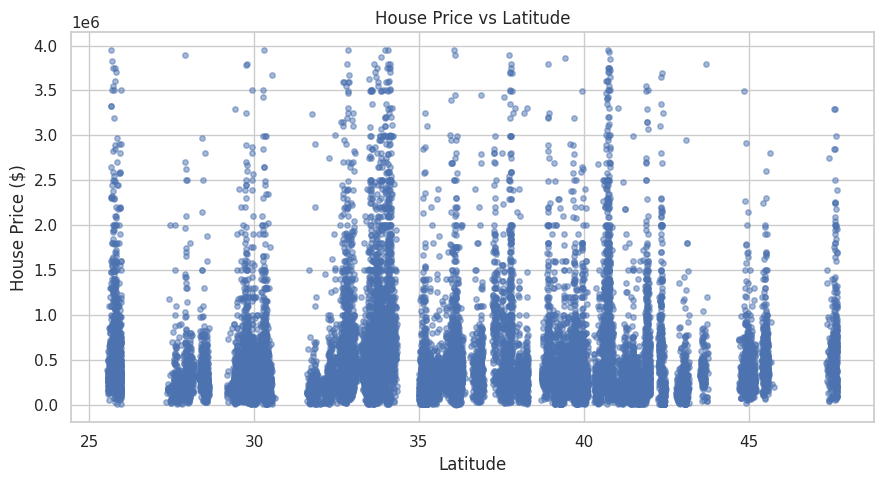

In [51]:
# This cell of code creates a common function to plot house price against a selected feature and remove rows with missing values for the selected feature and Price.
# Using the same function for different features instead of repeating plotting code.

def plot_price_relationship(data, column):
    if column not in data.columns:
        print(f"{column} is not available in the dataset.")
        return

    plot_data = data.dropna(subset=["Price", column]).copy()

    if plot_data.empty:
        print(f"No usable data for {column}.")
        return
## Reduces the displayed range so extreme values do not affect the graph's readability too much
    x_limit = plot_data[column].quantile(0.99)
    y_limit = plot_data["Price"].quantile(0.99)
    plot_data = plot_data[
        (plot_data[column] <= x_limit) &
        (plot_data["Price"] <= y_limit)
    ]

    plt.figure(figsize=(9, 5))
    plt.scatter(
        plot_data[column],
        plot_data["Price"],
        alpha=0.5,
        s=15
    )

    plt.xlabel(column)
    plt.ylabel("House Price ($)")
    plt.title(f"House Price vs {column}")
    plt.tight_layout()
    plt.show()


price_features_to_plot = [
    "Sqr Ft", "Beds", "Bath", "Year Built", "Lot Size",
    "Longitude", "Latitude"
]

for feature in price_features_to_plot:
    if feature in new_sheet.columns:
        plot_price_relationship(new_sheet, feature)


6.5 **Checks unusually large house sizes and prices**

In [52]:
for column in ["Sqr Ft", "Lot Size", "Price"]:
    if column in new_sheet.columns:
        print(f"\n{column} statistics:")
        display(new_sheet[column].describe(
            percentiles=[0.90, 0.95, 0.99]
        ))

if "Sqr Ft" in new_sheet.columns:
    display(
        new_sheet.nlargest(10, "Sqr Ft")[
            [c for c in ["Price", "Sqr Ft", "Beds", "Bath"] if c in new_sheet.columns]
        ]
    )


Sqr Ft statistics:


,Sqr Ft
count,27568.0
mean,5106.970727
std,249459.347741
min,1.0
50%,1800.0
90%,3571.0
95%,4513.0
99%,9000.0
max,36003799.0



Lot Size statistics:


,Lot Size
count,25278.0
mean,5380.813429
std,230148.656137
min,0.25
50%,3920.0
90%,8712.0
95%,9601.0
99%,10500.0
max,36590400.0



Price statistics:


,Price
count,29771.0
mean,529864.203386
std,1141364.054712
min,1.0
50%,309900.0
90%,960000.0
95%,1525500.0
99%,3950000.0
max,60000000.0


,Price,Sqr Ft,Beds,Bath
29728,399000,36003799,4.0,4.0
2107,1750000,20168280,<NA>,<NA>
28771,90000,1745014,<NA>,<NA>
27276,2690000,1494979,<NA>,<NA>
11114,149500,895419,<NA>,<NA>
27659,6300000,617569,2.0,2.0
18616,3650000,608532,2.0,3.0
16637,5295000,600613,3.0,3.0
8505,765000,593599,1.0,1.0
11206,810000,566824,1.0,1.0


7. **Prepares training and testing of data for regression**

Before training the regression models, I wanted to separate the input features from the target value beacuse in this project, the target is the house price, while the selected property and location columns are used as input features.

I have split the data into training and testing sets separately . The training data is used to teach the model while the testing data is used to check how well it predicts prices for records it has not seen before. Missing values are handled using values learned from the training data only.

In [53]:
## Code for Testing  and Training - separate the input features (X) from the target (y) and splitting the data into training and testing sets.
#Fit the median imputer using the training data only and then apply it to the test data.
##This actually helps me to prevent information from the test set leaking into training.

feature_columns = [
    "Sqr Ft", "Longitude", "Latitude", "Lot Size",
    "Beds", "Bath", "Year Built"
]

# Keeps the  only features that are actually present in this dataset..
feature_columns = [c for c in feature_columns if c in new_sheet.columns]

if not feature_columns:
    raise ValueError("No suitable predictor columns were found.")

X = new_sheet[feature_columns].copy()

y = new_sheet["Price"].copy()

# Ensures whether the  predictors are numeric
X = X.apply(pd.to_numeric, errors="coerce")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

regression_imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    regression_imputer.fit_transform(X_train),
    columns=feature_columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    regression_imputer.transform(X_test),
    columns=feature_columns,
    index=X_test.index
)
print("Features that are used:", feature_columns)

print("The Training data:", X_train.shape)

print("Testing's data:", X_test.shape)
print("Missing values in the training features:", X_train.isnull().sum().sum())

print("Missing values in the testing features:", X_test.isnull().sum().sum())

Features used: ['Sqr Ft', 'Longitude', 'Latitude', 'Lot Size', 'Beds', 'Bath', 'Year Built']
Training data: (23816, 7)
Testing data: (5955, 7)
Missing values in training features: 0
Missing values in testing features: 0


8. **Linear Regression**

I am starting with Linear Regression as the first house price prediction model. This model provides  a baseline by estimating the relationship between the selected input features and house price.

After training the model, I will use the test data to make predictions and calculate the evaluation scores. I will then compare these results with Random Forest Regression in the next section.

In [54]:
# #Linear Regression for house price prediction has been written and Trained the model using the training data.
# This code then predicts the house prices for the unseen test data and evaluate the model using MAE, MSE, RMSE and R squared.

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results below : ")

print("Mean Absolute Error(MAE) - ", round(mae, 2))
print("Mean Squared Error(MQE) -", round(mse, 2))
print("Root Mean Squared Error(RMQE) -", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Linear Regression Results
--------------------------
Mean Absolute Error: 350376.45
Mean Squared Error: 576118147229.65
Root Mean Squared Error: 759024.47
R2 Score: 0.2054


8.1 **Actual vs predicted house prices**

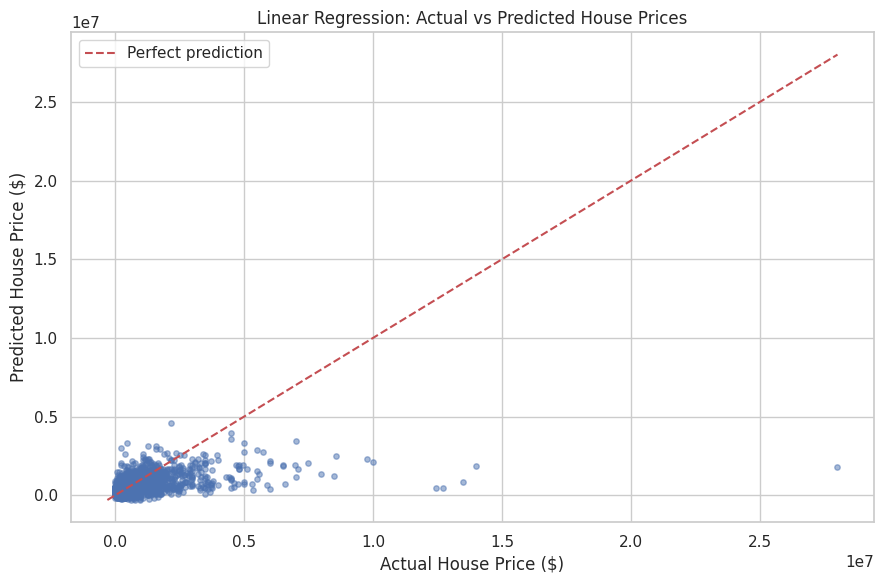

In [55]:
plt.figure(figsize=(9, 6))
plt.scatter(y_test, y_pred, alpha=0.5, s=15)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual House Price in $")
plt.ylabel("Predicted House Price in $")
plt.title("Linear Regression-  Actual vs Predicted House Prices")


plt.legend()
plt.tight_layout()
plt.show()

9. **Random Forest Regression**

In this section, I am applying Random Forest Regression to the same training and testing data I did before for Linear . Random Forest uses multiple decision trees and then combines their predictions which allows it to model more complex relationships in the dataset.

I will be able to compare its MAE, RMSE and Rsquared score with Linear Regression to see which model performs better on the test data.

In [56]:
# Random Forest Regression for house price prediction and training a collection of decision trees and combine their predictions.
# Predict house prices using the test data and calculate evaluation metrics.

forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_pred)
forest_mse = mean_squared_error(y_test, forest_pred)
forest_rmse = np.sqrt(forest_mse)
forest_r2 = r2_score(y_test, forest_pred)

print("Random Forest Regression Results")


print("Mean Absolute Error(MAE) -", round(forest_mae, 2))
print("Mean Squared Error(MQE) -", round(forest_mse, 2))
print("Root Mean Squared Error(RMSE) -", round(forest_rmse, 2))
print("R2 Score:", round(forest_r2, 4))

Random Forest Regression Results
--------------------------------
Mean Absolute Error: 184037.76
Mean Squared Error: 375613008064.2
Root Mean Squared Error: 612872.75
R2 Score: 0.482


9.1 **Compare regression models**

In [57]:
##Comparing  Linear Regression and Random Forest Regression where Lower MAE and RMSE indicate smaller prediction errors.
# From the code a higher R squared score indicates that more variation in house prices is explained.

regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "MAE": [mae, forest_mae],
    "RMSE": [rmse, forest_rmse],
    "R2 Score": [r2, forest_r2]
})


display(regression_results.sort_values("R2 Score", ascending=False))

,Model,MAE,RMSE,R2 Score
1,Random Forest Regression,184037.763682,612872.750303,0.481972
0,Linear Regression,350376.448709,759024.470771,0.205445


9.2 **Random Forest Regression feature importance**

,Feature,Importance
5,Bath,0.227717
1,Longitude,0.225265
0,Sqr Ft,0.209949
2,Latitude,0.129887
6,Year Built,0.093478
3,Lot Size,0.058790
4,Beds,0.054914


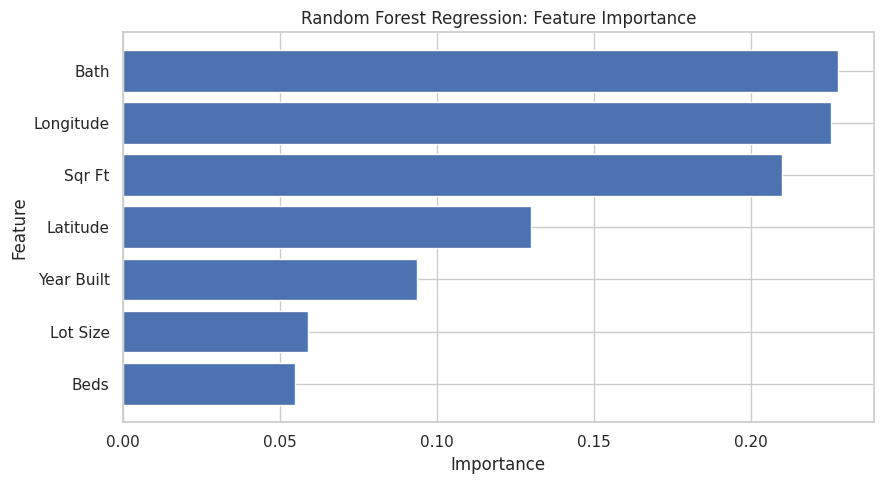

In [58]:
regression_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": forest_model.feature_importances_
}).sort_values("Importance", ascending=False)
display(regression_importance)

plt.figure(figsize=(9, 5))

plt.barh(
    regression_importance["Feature"],
    regression_importance["Importance"]
)
plt.xlabel("Importance")

plt.ylabel("Feature")

plt.title("Random Forest Regression - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

10. **K-Means clustering**

I am using K Means to explore whether the properties can be grouped based on the similar characteristics . So, unlike the  regression and  clustering models, it does not predict a continuous house price. Instead, it groups records according to similarities in the selected features.

The features are standardised even before applying K Means because the columns use different  scales. I will be creating and inspecting the elbow graph to understand how the within cluster sum of squares changes when the number of clusters increases.

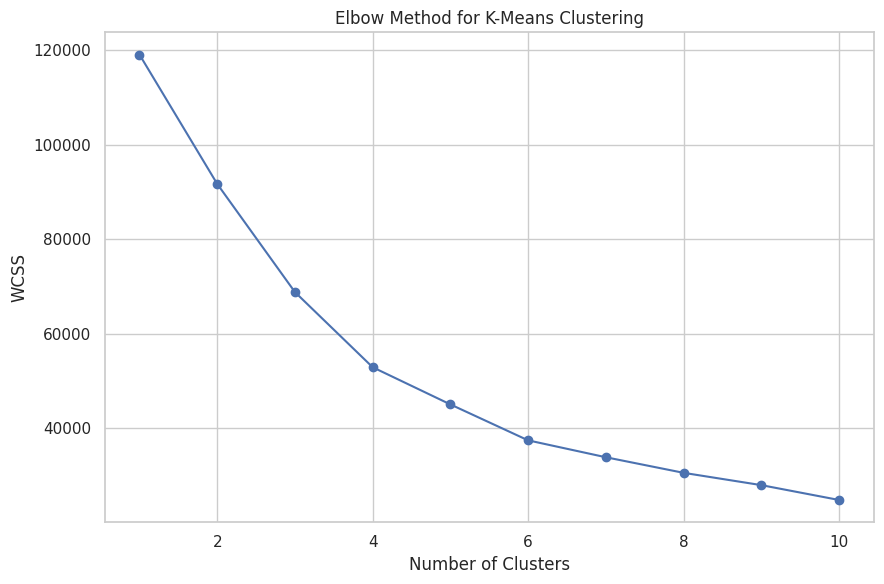

In [59]:
# I code prepares the numerical features for K-Means clustering and replaces missing values using the median before scaling.
#  And then standardise the features because the K-Means is affected by different feature scales.
# After that it will calculate WCSS for different cluster counts to inspect the elbow point.

cluster_features_base = ["Price", "Sqr Ft", "Beds", "Bath"]
cluster_features_base = [
    c for c in cluster_features_base if c in new_sheet.columns
]

cluster_data = new_sheet[cluster_features_base].copy()
cluster_data = cluster_data.apply(pd.to_numeric, errors="coerce")
cluster_data = cluster_data.dropna(subset=["Price"])

cluster_imputer = SimpleImputer(strategy="median")
cluster_values = cluster_imputer.fit_transform(cluster_data)

cluster_scaler = StandardScaler()
scaled_data = cluster_scaler.fit_transform(cluster_values)

wcss = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans_test.fit(scaled_data)
    wcss.append(kmeans_test.inertia_)

plt.figure(figsize=(9, 6))
plt.plot(list(cluster_range), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Within Cluster Sum of Squares")
plt.title("Elbow Method-- K-Means Clustering")
plt.tight_layout()
plt.show()

10.1 **Create four K-Means clusters**

In [60]:
## Here I will apply K-Means using four clusters as the selected starting choice add the cluster label to each property so that the groups can be analysed.

number_of_clusters = 4

kmeans_model = KMeans(
    n_clusters=number_of_clusters,
    random_state=42,
    n_init=10
)

cluster_data["Cluster"] = kmeans_model.fit_predict(scaled_data)

print("Number of houses in each of the cluster:")

display(cluster_data["Cluster"].value_counts().sort_index())

Number of houses in each cluster:


,count
Cluster,
0,8697
1,2
2,87
3,20985


10.2 **Visualise the clusters**

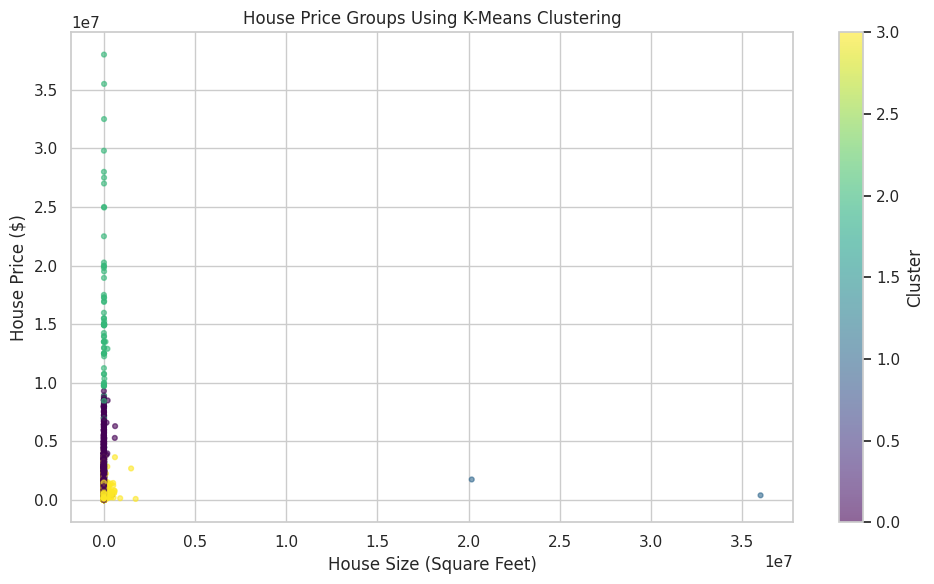

In [61]:
if {"Sqr Ft", "Price"}.issubset(cluster_data.columns):
    plt.figure(figsize=(10, 6))
    plt.scatter(
        cluster_data["Sqr Ft"],
        cluster_data["Price"],
        c=cluster_data["Cluster"],
        cmap="viridis",
        s=12,
        alpha=0.6
    )
    plt.xlabel("House Size sq")


    plt.ylabel("House Price in $")
    plt.title("House Price Groups Using K-Means Clustering")

    plt.colorbar(label="Cluster")


    plt.tight_layout()
    plt.show()

10.3 **Inspect the extreme values and repeat the clustering without the top 1 % of size and price**

In [62]:
cluster_sheet = cluster_data.copy()

if {"Sqr Ft", "Price"}.issubset(cluster_sheet.columns):
    size_limit = cluster_sheet["Sqr Ft"].quantile(0.99)
    price_limit = cluster_sheet["Price"].quantile(0.99)

    cluster_sheet = cluster_sheet[
        (cluster_sheet["Sqr Ft"] <= size_limit) &
        (cluster_sheet["Price"] <= price_limit)
    ].copy()

print("Records in the initial clustering are- ", len(cluster_data))

print("Records after limiting the extreme values are - ", len(cluster_sheet))

Records in initial clustering: 29771
Records after limiting extreme values: 27081


10.4 **K-Means after limiting the extreme values**

Number of houses in each cluster:


,count
Cluster,
0,6757
1,6306
2,12724
3,1294


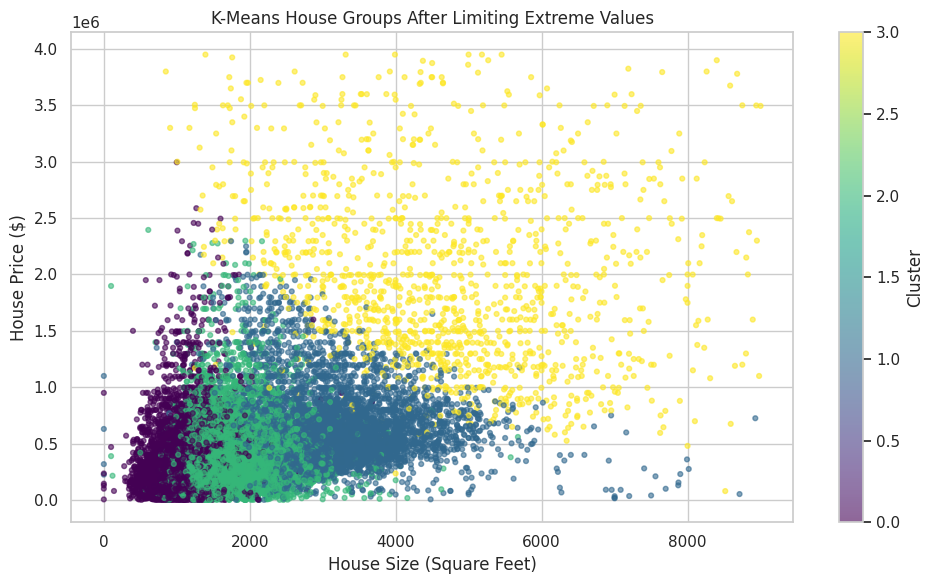

In [63]:
cluster_features = cluster_sheet[cluster_features_base].copy()
cluster_imputer_clean = SimpleImputer(strategy="median")

cluster_values_clean = cluster_imputer_clean.fit_transform(cluster_features)

scaler_clean = StandardScaler()

scaled_cluster_data = scaler_clean.fit_transform(cluster_values_clean)

kmeans_clean = KMeans(
    n_clusters=number_of_clusters,
    random_state=42,
    n_init=10
)

cluster_sheet["Cluster"] = kmeans_clean.fit_predict(scaled_cluster_data)

print("Number of houses in each of the cluster:")

display(cluster_sheet["Cluster"].value_counts().sort_index())

plt.figure(figsize=(10, 6))
plt.scatter(
    cluster_sheet["Sqr Ft"],
    cluster_sheet["Price"],
    c=cluster_sheet["Cluster"],
    cmap="viridis",
    s=12,
    alpha=0.6
)
plt.xlabel("House Size in Sq")
plt.ylabel("House Price in $")
plt.title("K-Means House Groups After Limiting the Extreme Values")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

10.5 **Summarise and review the clusters**

In [64]:
summary_columns = [
    c for c in ["Price", "Sqr Ft", "Beds", "Bath"]
    if c in cluster_sheet.columns
]

cluster_summary = cluster_sheet.groupby("Cluster")[summary_columns].mean().round(2)
print("Average values in each cluster:")
display(cluster_summary)

if len(cluster_sheet) > number_of_clusters:
    silhouette = silhouette_score(
        scaled_cluster_data,
        cluster_sheet["Cluster"],
        sample_size=min(3000, len(cluster_sheet)),
        random_state=42
    )
    print("the slhouette score:", round(silhouette, 4))
else:
  print("Not enough records to calculate a silhouette score.")

Average values in each cluster:


,Price,Sqr Ft,Beds,Bath
Cluster,,,,
0,299192.73,1091.65,2.02,1.42
1,584541.1,3056.14,4.31,3.53
2,324524.36,1775.85,3.23,2.37
3,1962707.43,4691.53,4.85,5.12


Silhouette Score: 0.2752


11. **Classification - predicting  the K-Means groups**

For the classification section, I have used the cluster labels created by k means as the target classes. I have trained a Decision Tree Classifier and a Random Forest Classifier to predict these groups from the selected features of the property.

This classification task predicts the groups produced by k- means and it does not directly classify house prices into real world price categories. Finally comparing the classifiers using accuracy, classification reports and a confusion matrix.

11.1 **Prepare classification training and testing data**

In [65]:
## preparing the classification dataset using the K-Means cluster labels as the target and Excluding the price from the classifier inputs so the model uses property features to predict the group.
# Then spliting the data and impute missing values using training data only.

    # Using  the same predictor columns as regression but excluding the price
classification_features = [
    c for c in feature_columns if c != "Price"
]
classification_features = [
    c for c in classification_features if c in new_sheet.columns
]

##  Aligns  the records with the rows that received cluster labels
X_class = new_sheet.loc[cluster_sheet.index, classification_features].copy()

y_class = cluster_sheet["Cluster"].copy()
X_class = X_class.apply(pd.to_numeric, errors="coerce")


X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

class_imputer = SimpleImputer(strategy="median")

X_train_class = pd.DataFrame(
    class_imputer.fit_transform(X_train_class),
    columns=classification_features,
    index=X_train_class.index
)
X_test_class = pd.DataFrame(
    class_imputer.transform(X_test_class),
    columns=classification_features,
    index=X_test_class.index
)

print("The classification features- ", classification_features)

print("Training data- ", X_train_class.shape)

print("Testing data- ", X_test_class.shape)
print("\nTraining cluster distribution- ")


display(y_train_class.value_counts().sort_index())

Classification features: ['Sqr Ft', 'Longitude', 'Latitude', 'Lot Size', 'Beds', 'Bath', 'Year Built']
Training data: (21664, 7)
Testing data: (5417, 7)

Training cluster distribution:


,count
Cluster,
0,5405
1,5045
2,10179
3,1035


11.2 **The Decision Tree Classification**

In [66]:
# This code is about training a decision tree classifier to predict the K Means cluster labels and evaluate its predictions using accuracy and a classification report.

tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

tree_model.fit(X_train_class, y_train_class)

tree_pred = tree_model.predict(X_test_class)

tree_accuracy = accuracy_score(y_test_class, tree_pred)

print("Decision Tree Classification Results are below- ")

print("Accuracy-", round(tree_accuracy, 4))
print("\nClassification Report-")

print(classification_report(y_test_class, tree_pred, zero_division=0))

Decision Tree Classification Results
-------------------------------------
Accuracy: 0.9457

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1352
           1       0.90      0.89      0.90      1261
           2       0.96      0.98      0.97      2545
           3       0.74      0.58      0.65       259

    accuracy                           0.95      5417
   macro avg       0.90      0.86      0.88      5417
weighted avg       0.94      0.95      0.94      5417



11.3 **The Decision Tree confusion matrix**

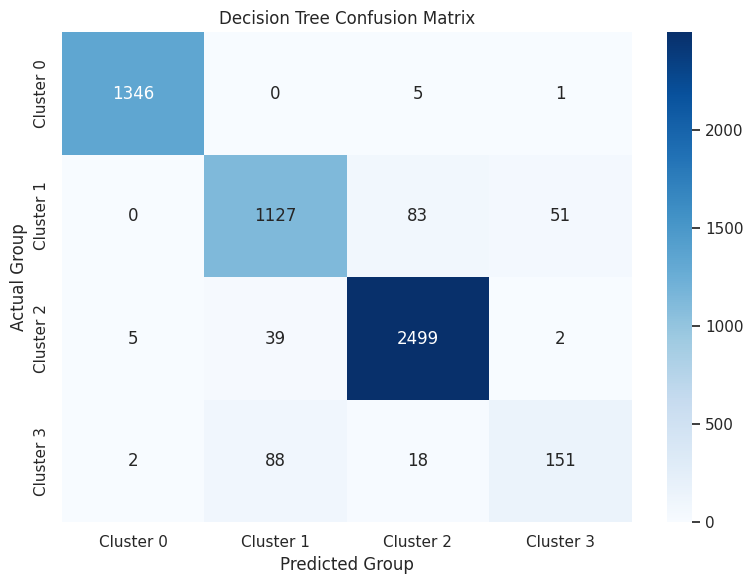

In [67]:
class_labels = sorted(y_class.unique())
cm = confusion_matrix(y_test_class, tree_pred, labels=class_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[f"Cluster {label}" for label in class_labels],
    yticklabels=[f"Cluster {label}" for label in class_labels]
)
plt.xlabel("Predicted Group")
plt.ylabel("Actual Group")
plt.title("Decision Tree Confusion Matrix")


plt.tight_layout()
plt.show()

11.4 **Random Forest Classification**

In [68]:
# This trains a Random Forest Classifier to predict the k means cluster labels and evaluate the predictions using accuracy and a classification report.

forest_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest_classifier.fit(X_train_class, y_train_class)
forest_class_pred = forest_classifier.predict(X_test_class)

forest_class_accuracy = accuracy_score(y_test_class, forest_class_pred)

print("Random Forest Classification Results")


print("Accuracy- ", round(forest_class_accuracy, 4))
print("\nClassification Report- ")


print(classification_report(
    y_test_class,
    forest_class_pred,
    zero_division=0
))

Random Forest Classification Results
-------------------------------------
Accuracy: 0.9581

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1352
           1       0.92      0.93      0.92      1261
           2       0.97      0.99      0.98      2545
           3       0.85      0.63      0.73       259

    accuracy                           0.96      5417
   macro avg       0.93      0.89      0.91      5417
weighted avg       0.96      0.96      0.96      5417



11.5 **Comparing Both Classification Models**

In [69]:
classification_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [tree_accuracy, forest_class_accuracy]
})


display(classification_results.sort_values("Accuracy", ascending=False))

,Model,Accuracy
1,Random Forest,0.958095
0,Decision Tree,0.945726


11.6 **Random Forest Classification feature's importance**

,Feature,Importance
0,Sqr Ft,0.302970
5,Bath,0.291559
4,Beds,0.269083
1,Longitude,0.039536
2,Latitude,0.032578
6,Year Built,0.032328
3,Lot Size,0.031946


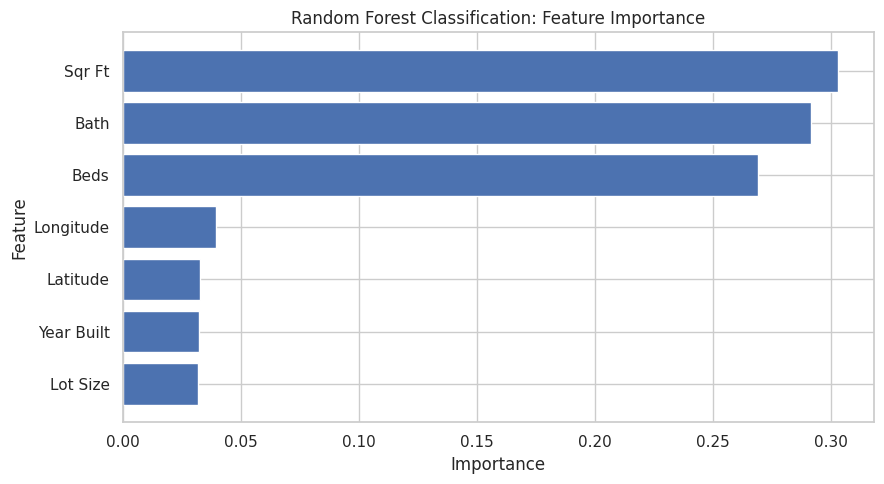

In [70]:
classification_importance = pd.DataFrame({
    "Feature": classification_features,
    "Importance": forest_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(classification_importance)

plt.figure(figsize=(9, 5))
plt.barh(
    classification_importance["Feature"],
    classification_importance["Importance"]
)
plt.xlabel("Importance")

plt.ylabel("Feature")

plt.title("Random Forest Classification: Feature Importance")


plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

12. **Final summary and personal reflections**



##**12.1 Summary of the Work**

In this assignment, I explored a house-price dataset and prepared it for machine learning. I started by checking the dataset, including its columns, data types, missing values and duplicate records.

I created a separate working copy and cleaned the data by converting numerical columns, filling missing ZIP codes where possible and removing unnecessary records and columns.

I then used graphs to explore house-price distribution, geographical patterns and relationships between property features.

For machine learning, I used Linear Regression and Random Forest Regression to predict house prices. I also applied K-Means clustering to group similar properties, followed by Decision Tree and Random Forest Classification to predict the cluster groups.

##**12.2 Model Comparison and Findings**

After comparing the regression models, Random Forest Regression performed better than Linear Regression.

Random Forest achieved an MAE of 184,036.31, an RMSE of 612,872.26 and an R-squared score of 0.481973. Linear Regression achieved an MAE of 350,376.22, an RMSE of 759,024.37 and an R-squared score of 0.205445.

For classification, Random Forest achieved 95.81% accuracy, compared with 94.57% for Decision Tree.

Overall, Random Forest performed better in both comparisons. However, the classification results represent predictions of the K-Means cluster groups, not actual house-price categories.

## **12.3 Personal Reflections**

While completing this assignment, I developed a better understanding of data cleaning, visualisation and machine learning. I learned the importance of handling missing values, selecting useful features and keeping a separate copy of the original dataset.

I also understood why training and testing data must be separated before fitting the imputer to avoid data leakage. Using different machine-learning algorithms helped me understand their purposes and how their performance can be compared.

If I were to improve this work further, I would investigate outliers, test different model settings and include additional property and geographical information to improve prediction accuracy.

Overall, this assignment gave me practical experience in applying different machine-learning techniques and evaluating their results.

## **12.4 Final Note**

Based on my results, Random Forest Regression was the best model for house-price prediction, while Random Forest Classification achieved the highest accuracy when predicting the K-Means groups.

## **My References**

I used the following websites to understand the Python code, data processing, visualisation and machine-learning methods used in this assignment as a reference:



1.   W3Schools - Pandas DataFrames: https://www.w3schools.com/python/pandas/pandas_dataframes.asp
2.   W3Schools - Pandas Cleaning: https://www.w3schools.com/python/pandas/pandas_cleaning.asp
3. Pandas - Reading Excel Files: https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html
4. Pandas - Converting Values to Numeric: https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html
5. NumPy - Percentiles: https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
6. Matplotlib - Histograms: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html
7. Seaborn - Heatmaps: https://seaborn.pydata.org/generated/seaborn.heatmap.html
8. Scikit-learn - Regression Models: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

9. Scikit-learn - Classification Models:https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

10. Scikit-learn - K-Means Clustering:https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html


